# 17. Capstone: the onset of Rayleigh–Bénard convection

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/17_capstone_rayleigh_benard.ipynb)

*Goes beyond L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000), using the tools built in notebooks 1 to 14.*

Heat a horizontal layer of fluid gently from below and nothing moves: the heat is conducted.
Heat it a little harder and the layer breaks into a regular pattern of rolls. The threshold is
one of the most famous numbers of transport phenomena, a critical Rayleigh number of 1707.762
between two rigid plates. This capstone computes it from the governing equations, with every
step taken from an earlier notebook.

- the linear stability equations, derived and scaled from the Boussinesq equations
- three classical sets of boundary conditions, one of them with an exact answer
- the neutral curves, the critical Rayleigh numbers and the shape of the convection rolls
- growth rates, and why the threshold does not depend on the Prandtl number

**Worked example:** the temperature difference at which a 5 mm layer of water starts to convect.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig, solve
from scipy.optimize import minimize_scalar

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 17.1 The problem and the plan

**Problem.** A fluid layer of depth $d$ lies between two horizontal plates. The lower plate is
hotter than the upper one by $\Delta T$. Warm fluid at the bottom is lighter than the cold fluid
above it, so buoyancy would like to turn the layer over, while viscosity and heat conduction
resist. Find the temperature difference at which buoyancy wins, and the pattern that appears.

The plan, and where each step comes from:

| Step | Tool | Notebook |
| --- | --- | --- |
| discretize $d/dz$ across the layer | Chebyshev matrix `cheb(N)`, mapped to $[0, 1]$ | 5 |
| fixed temperature and no flow through the plates | Dirichlet conditions by deleting rows and columns | 6 |
| no-slip plates, $W = W' = 0$ | clamped fourth-order operator, $W = (1 - x^2)\,q$ | 14 |
| stress-free surface, $W = W'' = 0$ | boundary conditions as replaced rows | 13 |
| neutral Rayleigh number for each wavenumber | generalized matrix eigenproblem | 8 |
| which computed eigenvalues to trust | compare two resolutions | 8, 16 |
| growth rates in time | eigenvalues of the method-of-lines operator | 9 |
| the answer is right | exact solution, published values, convergence with $N$ | every notebook |

## 17.2 The linear stability equations

**By hand.** Start from the Boussinesq equations: the fluid is incompressible and its density
varies only in the buoyancy term, $\rho = \rho_0\,[1 - \beta\,(T - T_0)]$. With $z$ pointing
upwards, and with $p$ the pressure after its hydrostatic part $-\rho_0 g z$ has been removed,

$$\nabla\cdot\mathbf{u} = 0,\qquad
\frac{\partial \mathbf{u}}{\partial t} + \mathbf{u}\cdot\nabla\mathbf{u}
  = -\frac{1}{\rho_0}\nabla p + g\beta\,(T - T_0)\,\mathbf{e}_z + \nu\nabla^2\mathbf{u},\qquad
\frac{\partial T}{\partial t} + \mathbf{u}\cdot\nabla T = \kappa\nabla^2 T .$$

**The conduction state.** With the fluid at rest the temperature falls linearly from the hot
plate at $z = 0$ to the cold plate at $z = d$: $\bar T(z) = T_{\text{hot}} - \Delta T\,z/d$.
The pressure balances the buoyancy and nothing moves.

**Linearize.** Add a small disturbance: velocity $\mathbf{u} = (u, v, w)$ and temperature
$\bar T + \theta$. Products of small quantities are dropped. The only term in which the base
state survives is $\mathbf{u}\cdot\nabla\bar T = -w\,\Delta T/d$: rising fluid ($w > 0$)
carries warm fluid upwards. The disturbance equations are

$$\frac{\partial \mathbf{u}}{\partial t} = -\frac{1}{\rho_0}\nabla p' + g\beta\,\theta\,\mathbf{e}_z + \nu\nabla^2\mathbf{u},
\qquad \frac{\partial \theta}{\partial t} - \frac{\Delta T}{d}\,w = \kappa\nabla^2\theta .$$

**Scale.** Measure lengths in $d$, time in $d^2/\kappa$, velocity in $\kappa/d$, temperature
in $\Delta T$ and pressure in $\rho_0\nu\kappa/d^2$. Two dimensionless groups appear:

$$Ra = \frac{g\beta\,\Delta T\,d^3}{\nu\kappa}\quad\text{(Rayleigh number)},\qquad
Pr = \frac{\nu}{\kappa}\quad\text{(Prandtl number)},$$

and the equations become

$$\frac{1}{Pr}\frac{\partial \mathbf{u}}{\partial t} = -\nabla p' + Ra\,\theta\,\mathbf{e}_z + \nabla^2\mathbf{u},
\qquad \frac{\partial \theta}{\partial t} = w + \nabla^2\theta .$$

**Eliminate the pressure.** Take the curl of the momentum equation twice and keep the vertical
component. With $\nabla\cdot\mathbf{u} = 0$ the identity
$\nabla\times\nabla\times\mathbf{a} = \nabla(\nabla\cdot\mathbf{a}) - \nabla^2\mathbf{a}$ gives

$$\frac{1}{Pr}\frac{\partial}{\partial t}\nabla^2 w = \nabla^4 w + Ra\,\nabla_h^2\theta,
\qquad \nabla_h^2 = \frac{\partial^2}{\partial x^2} + \frac{\partial^2}{\partial y^2} .$$

Only horizontal *variations* of temperature drive a flow, which is why the horizontal Laplacian
appears: a layer that is warmer everywhere by the same amount is balanced by pressure alone.

**Normal modes.** The coefficients do not depend on $x$, $y$ or $t$, so the solutions are
$w = W(z)\,e^{ikx + \sigma t}$ and $\theta = \Theta(z)\,e^{ikx + \sigma t}$. Then
$\nabla_h^2 \to -k^2$ and $\nabla^2 \to D^2 - k^2$ with $D = d/dz$. (The $x$ axis has been
laid across the rolls. A general horizontal dependence $e^{i(k_x x + k_y y)}$ gives the same
equations with $k^2 = k_x^2 + k_y^2$.)

$$\boxed{\;(D^2 - k^2)^2\,W - Ra\,k^2\,\Theta = \frac{\sigma}{Pr}\,(D^2 - k^2)\,W,
\qquad (D^2 - k^2)\,\Theta + W = \sigma\,\Theta\;}\qquad 0 \le z \le 1 .$$

A sign check: at the threshold $\sigma = 0$, the second equation gives
$W = -(D^2 - k^2)\Theta$, and substituting $\Theta$ from the first leaves the single
sixth-order equation $(D^2 - k^2)^3 W = -Ra\,k^2\,W$, the classical form.

**Boundary conditions.** Both plates are held at fixed temperature and are impermeable:
$\Theta = 0$ and $W = 0$. A **rigid** plate is also no-slip. The horizontal velocities vanish
along it, so by continuity $\partial w/\partial z = 0$: $DW = 0$. A **free** surface carries
no shear stress instead, which gives $D^2 W = 0$. Six conditions for a sixth-order problem.

The layer is stable if the real part of $\sigma$ is negative for every wavenumber $k$. The
**neutral curve** $Ra(k)$ is where $\sigma = 0$, and its lowest point is the critical Rayleigh
number $Ra_c$. (Section 17.8 checks that $\sigma$ is real where it changes sign.)

## 17.3 Two free surfaces: the case with an exact answer

**By hand.** With free surfaces at $z = 0$ and $z = 1$ every boundary condition is satisfied
by $W = \sin \pi z$ (then $\Theta \propto \sin\pi z$ too). Each $D^2 - k^2$ becomes the number
$-(\pi^2 + k^2)$, and the sixth-order equation reduces to algebra:

$$Ra(k) = \frac{(\pi^2 + k^2)^3}{k^2},\qquad
\frac{dRa}{dk} = 0 \;\Rightarrow\; k_c = \frac{\pi}{\sqrt2} = 2.2214,\quad Ra_c = \frac{27\pi^4}{4} = 657.5114 .$$

This is Rayleigh's result of 1916. It is the test case for the numerical method.

**Discretization.** The Chebyshev points $x_j = \cos(j\pi/N)$ on $[-1, 1]$ are mapped to the
layer by $z = (x + 1)/2$, so $d/dz = 2\,d/dx$. Index 0 is the top plate $z = 1$ and index $N$
is the bottom plate $z = 0$. Deleting the first and last rows and columns of $D^2 - k^2 I$
gives a matrix $L$ that acts on functions vanishing at both plates.

At $\sigma = 0$ the two boxed equations, written for the interior values of $W$ and $\Theta$,
are a **generalized eigenproblem** $A\,\mathbf{x} = Ra\,B\,\mathbf{x}$ in which the eigenvalue
is the Rayleigh number:

$$\begin{pmatrix} L_4 & 0 \\ I & L \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}
= Ra \begin{pmatrix} 0 & k^2 I \\ 0 & 0 \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}.$$

$L_4$ is the matrix of $(D^2 - k^2)^2$ acting on $W$, and it is the only block that knows
whether the plates are rigid or free. For free surfaces $L_4 = L^2$: applying $L$ twice forces
both $W$ and $(D^2 - k^2)W$ to vanish at the plates, and since $W = 0$ there this is
$D^2 W = 0$.

The matrix $B$ is singular, so half of the eigenvalues are infinite. The finite ones
approximate the neutral Rayleigh numbers of the successive vertical mode shapes (one cell
across the layer, two cells, and so on). The smallest is the neutral Rayleigh number $Ra(k)$.

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def helmholtz(k, N):
    """Matrix L of D² − k² on the interior points of the layer 0 < z < 1 (values zero at both plates)."""
    D, x = cheb(N)
    D = 2 * D                                                   # d/dz = 2 d/dx, because z = (x + 1)/2
    return (D @ D)[1:-1, 1:-1] - k**2 * np.eye(N - 1)

def positive_real(eigenvalues):
    """The finite, real, positive eigenvalues in increasing order."""
    lam = eigenvalues[np.isfinite(eigenvalues)]
    lam = lam[(np.abs(lam.imag) < 1e-6 * np.abs(lam)) & (lam.real > 0)]
    return np.sort(lam.real)

def neutral_rayleigh(k, L, L4):
    """Neutral Rayleigh numbers at wavenumber k, lowest first, from the blocks L and L4."""
    n = len(L)
    A = np.block([[L4, np.zeros((n, n))], [np.eye(n), L]])
    B = np.block([[np.zeros((n, n)), k**2 * np.eye(n)], [np.zeros((n, n)), np.zeros((n, n))]])
    return positive_real(eig(A, B, right=False))

def ra_free_free(k, N=20):
    L = helmholtz(k, N)
    return neutral_rayleigh(k, L, L @ L)[0]

**Verify** the whole neutral curve against Rayleigh's formula, then the minimum.

In [3]:
k_test = np.linspace(1.0, 6.0, 11)
exact_curve = (np.pi**2 + k_test**2) ** 3 / k_test**2
computed_curve = np.array([ra_free_free(k) for k in k_test])
print(f"largest relative error of Ra(k) on 1 <= k <= 6: {np.abs(computed_curve / exact_curve - 1).max():.1e}")
assert np.abs(computed_curve / exact_curve - 1).max() < 1e-8

def critical_point(ra_of_k, bracket):
    """Minimum of a neutral curve: returns (k_c, Ra_c)."""
    best = minimize_scalar(ra_of_k, bounds=bracket, method="bounded", options={"xatol": 1e-7})
    return best.x, best.fun

k_ff, Ra_ff = critical_point(ra_free_free, (1.0, 4.0))
print(f"free-free:   Ra_c = {Ra_ff:.4f}   k_c = {k_ff:.4f}     exact: {27 * np.pi**4 / 4:.4f} and {np.pi / np.sqrt(2):.4f}")
assert abs(Ra_ff - 27 * np.pi**4 / 4) < 1e-6 and abs(k_ff - np.pi / np.sqrt(2)) < 1e-4

largest relative error of Ra(k) on 1 <= k <= 6: 6.3e-11
free-free:   Ra_c = 657.5114   k_c = 2.2214     exact: 657.5114 and 2.2214


The exact values are reproduced with 21 points across the layer. The minimum of the curve is
flat, so $k_c$ is always known to about half as many digits as $Ra_c$: an error $\delta$ in $k$
changes $Ra$ only by an amount of order $\delta^2$.

Free surfaces on both sides are hard to realize in a laboratory. The case matters because it
can be solved by hand, and because it gives the right order of magnitude.

## 17.4 Two rigid plates: 1707.762

**Problem.** The practical case: fluid between two solid, well-conducting plates. Now
$W = DW = 0$ at both plates, which is the **clamped** condition of a beam in notebook 14. No
simple formula exists. The classical value, tabulated by Chandrasekhar (*Hydrodynamic and
Hydromagnetic Stability*, 1961), is $Ra_c = 1707.762$ at $k_c = 3.117$.

**By hand.** Two conditions at each end are more than the two boundary rows can hold. The
remedy of notebook 14 is to write, in the Chebyshev variable $x$,

$$W(x) = (1 - x^2)\,q(x),\qquad q(\pm1) = 0 .$$

Then $W(\pm1) = 0$, and $W' = -2xq + (1 - x^2)q'$ vanishes at $x = \pm1$ as well. The product
rule gives the fourth derivative in terms of $q$:

$$W'''' = (1 - x^2)\,q'''' - 8x\,q''' - 12\,q'' .$$

So with $q = W/(1 - x^2)$ at the interior points, the fourth-derivative matrix for clamped
functions is $\big[\operatorname{diag}(1 - x^2)\,D^4 - 8\operatorname{diag}(x)\,D^3 - 12\,D^2\big]\operatorname{diag}\!\big(1/(1 - x^2)\big)$,
restricted to interior rows and columns. On the layer each derivative brings a factor 2, so
the matrix is multiplied by $2^4$. Then

$$L_4 = D^4_{\text{clamped}} - 2k^2 D^2 + k^4 I .$$

In [4]:
# clamped_d4(N) from notebook 14
def clamped_d4(N):
    """Fourth-derivative matrix on the interior Chebyshev points for functions with u = u' = 0 at x = ±1."""
    D, x = cheb(N)
    D2 = D @ D
    D3, D4 = D2 @ D, D2 @ D2
    weight = np.zeros(N + 1)
    weight[1:-1] = 1 / (1 - x[1:-1] ** 2)
    operator = (np.diag(1 - x**2) @ D4 - 8 * np.diag(x) @ D3 - 12 * D2) @ np.diag(weight)
    return operator[1:-1, 1:-1]

def rigid_blocks(k, N):
    """L and L4 for a layer between two rigid plates."""
    L = helmholtz(k, N)
    identity = np.eye(N - 1)
    D2 = L + k**2 * identity
    return L, 16 * clamped_d4(N) - 2 * k**2 * D2 + k**4 * identity

def ra_rigid_rigid(k, N=20, mode=0):
    return neutral_rayleigh(k, *rigid_blocks(k, N))[mode]

# the clamped operator on a function it must differentiate exactly: u = (1 − x²)², u'''' = 24
_, x = cheb(12)
assert np.abs(clamped_d4(12) @ ((1 - x[1:-1] ** 2) ** 2) - 24).max() < 1e-8

k_rr, Ra_rr = critical_point(ra_rigid_rigid, (2.0, 5.0))
print(f"rigid-rigid: Ra_c = {Ra_rr:.4f}   k_c = {k_rr:.4f}")
assert abs(Ra_rr - 1707.762) < 5e-4            # seven significant digits
assert abs(k_rr - 3.117) < 1e-3
assert 0 < ra_rigid_rigid(3.117) - Ra_rr < 2e-4       # the minimum is very flat

rigid-rigid: Ra_c = 1707.7618   k_c = 3.1163


The famous number, to seven significant digits. The wavenumber comes out as 3.1163. The
classical table gives 3.117. The difference in the fourth digit reflects how flat the minimum
is: at $k = 3.117$ the neutral Rayleigh number is larger by only 0.0001.

**Verify the convergence.** A published value is one check. The other is that the answer stops
changing when $N$ grows.

  N    Ra(k_c)
  6   1707.5286714
  8   1707.7597890
 10   1707.7617767
 12   1707.7617772
 14   1707.7617771
 16   1707.7617771


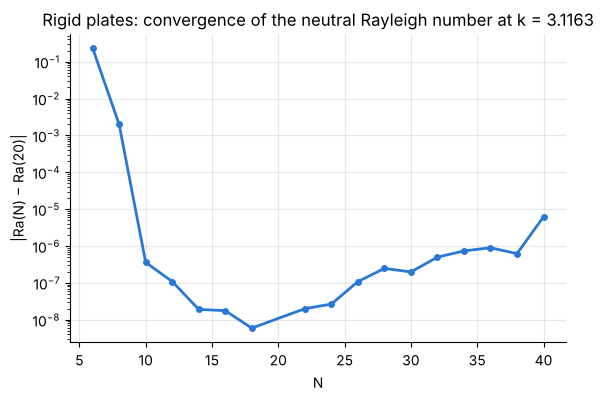

In [5]:
N_list = np.arange(6, 41, 2)
Ra_of_N = np.array([ra_rigid_rigid(k_rr, N) for N in N_list])
reference = Ra_of_N[N_list == 20][0]
change = np.abs(Ra_of_N - reference)

print("  N    Ra(k_c)")
for N, value in zip(N_list[:6], Ra_of_N[:6]):
    print(f"{N:3d}   {value:.7f}")
assert np.abs(Ra_of_N[(N_list >= 12) & (N_list <= 30)] - 1707.762).max() < 5e-4
assert abs(Ra_of_N[N_list == 8][0] - reference) < 0.01          # six digits from nine points

fig, ax = plt.subplots()
ax.semilogy(N_list[N_list != 20], change[N_list != 20], "o-", ms=4)
ax.set(xlabel="N", ylabel="|Ra(N) − Ra(20)|", title="Rigid plates: convergence of the neutral Rayleigh number at k = 3.1163");

Nine points across the layer ($N = 8$) already give six digits, and eleven points give nine.
Beyond $N \approx 16$ the result does not improve. It slowly gets worse, because the
fourth-derivative matrix has entries of size $N^8$ and amplifies rounding errors (notebook 16
discusses this). Even at $N = 40$ the damage is only in the ninth digit, but the message of
notebook 5 stands: use the $N$ the problem needs. Here that is between 12 and 20. (The
reference value $Ra(20)$ carries the same rounding noise, of about $10^{-8}$, which is the
floor of the plot.)

## 17.5 One rigid plate and one free surface

**Problem.** A liquid layer on a hot plate, open to the air above, is closer to a rigid bottom
and a free top (if surface tension effects are ignored). The published value is
$Ra_c = 1100.650$ at $k_c = 2.682$.

**By hand.** The clamped substitution no longer fits, because the two ends differ. The general
method of notebook 13 does: keep all $N + 1$ values of $W$ and $\Theta$ as unknowns and
**replace rows** of the eigenproblem by boundary conditions. The fourth-order equation needs
two conditions at each end, so two rows are given up at each end: the boundary row itself
carries $W = 0$, and its neighbour carries $DW = 0$ (rigid) or $D^2W = 0$ (free). The rows of
$B$ are set to zero in the same places, so the conditions hold for every eigenvalue.

In [6]:
def ra_general(k, N=20, bottom="rigid", top="free"):
    """Lowest neutral Rayleigh number with any combination of rigid and free boundaries (row replacement)."""
    D, x = cheb(N)
    D = 2 * D
    D2, identity, zero = D @ D, np.eye(N + 1), np.zeros((N + 1, N + 1))
    L = D2 - k**2 * identity
    A = np.block([[L @ L, zero], [identity, L]])
    B = np.block([[zero, k**2 * identity], [zero, zero]])
    # index 0 is the top plate z = 1, index N is the bottom plate z = 0
    for edge, neighbour, kind in ((0, 1, top), (N, N - 1, bottom)):
        rows = [edge, neighbour, N + 1 + edge]
        A[rows, :], B[rows, :] = 0.0, 0.0
        A[edge, edge] = 1.0                                              # W = 0
        A[neighbour, :N + 1] = D[edge] if kind == "rigid" else D2[edge]  # DW = 0 or D²W = 0
        A[N + 1 + edge, N + 1 + edge] = 1.0                              # Θ = 0
    return positive_real(eig(A, B, right=False))[0]

**Verify** the new construction on the two cases already solved, which it must reproduce,
before trusting it on the third.

In [7]:
for bottom, top, known in (("free", "free", ra_free_free(2.0)), ("rigid", "rigid", ra_rigid_rigid(2.0))):
    value = ra_general(2.0, bottom=bottom, top=top)
    print(f"{bottom}-{top} at k = 2: row replacement {value:.6f}   earlier method {known:.6f}")
    assert abs(value / known - 1) < 1e-8

k_rf, Ra_rf = critical_point(ra_general, (1.5, 4.0))
print(f"rigid-free:  Ra_c = {Ra_rf:.4f}   k_c = {k_rf:.4f}")
assert abs(Ra_rf - 1100.650) < 5e-4 and abs(k_rf - 2.682) < 1e-3
assert abs(ra_general(k_rf, N=28) - Ra_rf) < 1e-5                        # unchanged at a higher resolution

free-free at k = 2: row replacement 667.009824   earlier method 667.009824
rigid-rigid at k = 2: row replacement 2177.412086   earlier method 2177.412086
rigid-free:  Ra_c = 1100.6496   k_c = 2.6823


Two independent constructions agree to eight digits where they overlap, and the third classical
number follows.

## 17.6 The three neutral curves

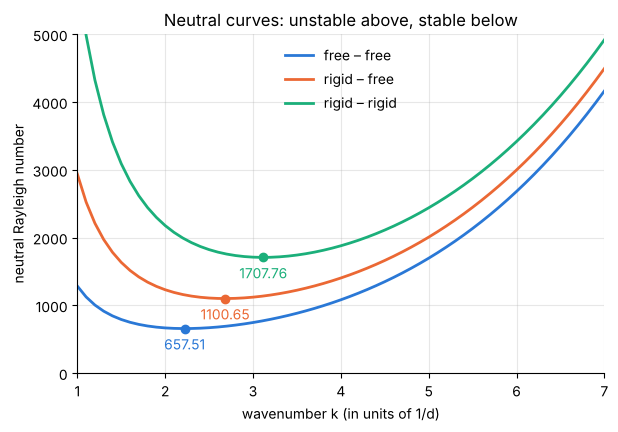

In [8]:
k_plot = np.linspace(1.0, 7.0, 61)
cases = {"free – free": (ra_free_free, k_ff, Ra_ff), "rigid – free": (ra_general, k_rf, Ra_rf),
         "rigid – rigid": (ra_rigid_rigid, k_rr, Ra_rr)}

fig, ax = plt.subplots(figsize=(6.8, 4.4))
for name, (curve, kc, Rac) in cases.items():
    line, = ax.plot(k_plot, [curve(k) for k in k_plot], label=name)
    ax.plot(kc, Rac, "o", color=line.get_color())
    ax.annotate(f"{Rac:.2f}", (kc, Rac), xytext=(0, -15), textcoords="offset points", ha="center", color=line.get_color())
ax.set(xlabel="wavenumber k (in units of 1/d)", ylabel="neutral Rayleigh number", ylim=(0, 5000), xlim=(1, 7),
       title="Neutral curves: unstable above, stable below")
ax.legend(frameon=False, loc="upper center");

In [9]:
print("boundaries       Ra_c        k_c     roll width π/k_c (layer depths)")
for name, (curve, kc, Rac) in cases.items():
    print(f"{name:14s} {Rac:9.3f}   {kc:7.4f}   {np.pi / kc:6.3f}")
assert Ra_ff < Ra_rf < Ra_rr and k_ff < k_rf < k_rr

boundaries       Ra_c        k_c     roll width π/k_c (layer depths)
free – free      657.511    2.2214    1.414
rigid – free    1100.650    2.6823    1.171
rigid – rigid   1707.762    3.1163    1.008


Above its curve a disturbance of wavenumber $k$ grows, below it decays. Below the minimum
nothing grows at all. Each rigid plate adds friction, so it raises the threshold and makes the
rolls narrower. Both very wide rolls (small $k$) and very narrow ones (large $k$) are harder to
drive: wide rolls move fluid a long way horizontally for little vertical heat transport, and
narrow rolls lose their temperature contrast to conduction between neighbours.

## 17.7 The critical mode: convection rolls

The eigenvector at the critical point is the flow pattern that appears first. The real fields
are $w = W(z)\cos kx$ and $\theta = \Theta(z)\cos kx$. For a two-dimensional incompressible
flow a stream function $\psi$ with $u = \partial\psi/\partial z$, $w = -\partial\psi/\partial x$
gives the streamlines, and here $\psi = -W(z)\sin(kx)/k$.

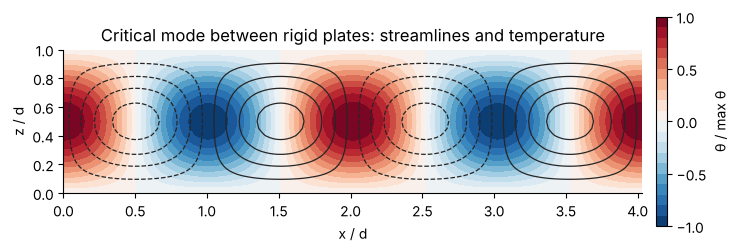

In [10]:
N = 32
L, L4 = rigid_blocks(k_rr, N)
n = N - 1
A = np.block([[L4, np.zeros((n, n))], [np.eye(n), L]])
B = np.block([[np.zeros((n, n)), k_rr**2 * np.eye(n)], [np.zeros((n, n)), np.zeros((n, n))]])
values, vectors = eig(A, B)
finite = np.isfinite(values)
values, vectors = values[finite], vectors[:, finite]
closest = np.argmin(np.abs(values - Ra_rr))
mode = vectors[:, closest].real
z = (cheb(N)[1] + 1) / 2
W = np.r_[0.0, mode[:n], 0.0]
Theta = np.r_[0.0, mode[n:], 0.0]
scale = W[np.argmax(np.abs(W))]
W, Theta = W / scale, Theta / scale

assert abs(values[closest].real - Ra_rr) < 1e-4 and np.abs(vectors[:, closest].imag).max() < 1e-8
assert np.all(W >= 0) and np.all(Theta >= 0)                 # rising fluid is warm fluid
assert np.abs(W - W[::-1]).max() < 1e-6                      # symmetric about the mid-plane

x_roll = np.linspace(0, 4 * np.pi / k_rr, 161)               # two wavelengths
theta_field = np.outer(Theta / Theta.max(), np.cos(k_rr * x_roll))
psi_field = -np.outer(W, np.sin(k_rr * x_roll)) / k_rr

fig, ax = plt.subplots(figsize=(9, 3.2))
filled = ax.contourf(x_roll, z, theta_field, levels=np.linspace(-1, 1, 21), cmap="RdBu_r")
ax.contour(x_roll, z, psi_field, levels=[-0.28, -0.2, -0.12, -0.04, 0.04, 0.12, 0.2, 0.28], colors="0.15", linewidths=0.9)
ax.set(xlabel="x / d", ylabel="z / d", aspect="equal",
       title="Critical mode between rigid plates: streamlines and temperature")
ax.grid(False)
fig.colorbar(filled, ax=ax, label="θ / max θ", shrink=0.85, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1]);

Warm fluid (red) rises, cold fluid (blue) sinks, and neighbouring rolls turn in opposite
directions like meshed gears (solid and dashed streamlines). Each roll is $\pi/k_c = 1.008$ layer depths wide: the rolls are
very nearly square in cross-section. The amplitude is arbitrary, because a linear theory fixes
the shape of the disturbance and not its size.

## 17.8 Growth rates and the Prandtl number

**Problem.** The neutral curve came from setting $\sigma = 0$. That is only justified if the
growth rate passes through zero as a real number. If $\sigma$ were complex at the threshold,
the instability would set in as an oscillation, and at a different Rayleigh number. Solve the
full problem for $\sigma$ and check. The Prandtl number, absent at $\sigma = 0$, now enters.

The boxed equations of 17.2 are a generalized eigenproblem for $\sigma$ at fixed $Ra$:

$$\begin{pmatrix} L_4 & -Ra\,k^2 I \\ I & L \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}
= \sigma \begin{pmatrix} L/Pr & 0 \\ 0 & I \end{pmatrix}\begin{pmatrix} \mathbf{W} \\ \boldsymbol{\Theta} \end{pmatrix}.$$

**By hand, for a check.** With free surfaces and $W = \sin\pi z$ the problem is again
algebraic. Writing $K^2 = \pi^2 + k^2$, the two equations combine into a quadratic for $\sigma$:

$$K^2\,(\sigma + K^2)\Big(\frac{\sigma}{Pr} + K^2\Big) = Ra\,k^2 .$$

In [11]:
def growth_rate(Ra, Pr, k, L, L4):
    """The eigenvalue σ with the largest real part (returned as a complex number)."""
    n = len(L)
    A = np.block([[L4, -Ra * k**2 * np.eye(n)], [np.eye(n), L]])
    B = np.block([[L / Pr, np.zeros((n, n))], [np.zeros((n, n)), np.eye(n)]])
    sigma = eig(A, B, right=False)
    return sigma[np.argmax(sigma.real)]

# verify against the quadratic for free surfaces, on both sides of the threshold
for Ra, Pr in ((400.0, 0.7), (1500.0, 0.7), (1500.0, 7.0)):
    L = helmholtz(k_ff, 20)
    K2 = np.pi**2 + k_ff**2
    exact = np.roots([K2 / Pr, K2**2 * (1 + 1 / Pr), K2**3 - Ra * k_ff**2]).max()
    sigma = growth_rate(Ra, Pr, k_ff, L, L @ L)
    print(f"free-free, Ra = {Ra:6.0f}, Pr = {Pr}: σ = {sigma.real:10.6f}   exact {exact:10.6f}")
    assert abs(sigma.real - exact) < 1e-5 and abs(sigma.imag) < 1e-9

free-free, Ra =    400, Pr = 0.7: σ =  -2.670898   exact  -2.670898
free-free, Ra =   1500, Pr = 0.7: σ =   6.255890   exact   6.255890
free-free, Ra =   1500, Pr = 7.0: σ =  14.758984   exact  14.758984


Pr = 0.7: σ =   -6.604 at 0.5 Ra_c,     1.6e-10 at Ra_c,     5.121 at 1.5 Ra_c
Pr = 7.0: σ =   -9.452 at 0.5 Ra_c,    -1.5e-10 at Ra_c,     8.891 at 1.5 Ra_c


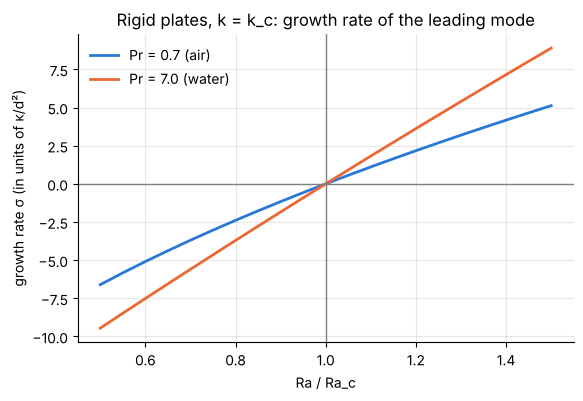

In [12]:
L, L4 = rigid_blocks(k_rr, 20)
ratios = np.linspace(0.5, 1.5, 21)
fig, ax = plt.subplots()
for Pr in (0.7, 7.0):
    sigma = np.array([growth_rate(ratio * Ra_rr, Pr, k_rr, L, L4) for ratio in ratios])
    assert np.abs(sigma.imag).max() < 1e-8                               # real: no oscillation
    assert np.all(sigma.real[ratios < 0.999] < 0) and np.all(sigma.real[ratios > 1.001] > 0)
    assert abs(growth_rate(Ra_rr, Pr, k_rr, L, L4).real) < 1e-6          # zero at the same Ra_c for both
    ax.plot(ratios, sigma.real, label=f"Pr = {Pr} ({'air' if Pr < 1 else 'water'})")
    print(f"Pr = {Pr}: σ = {sigma.real[0]:8.3f} at 0.5 Ra_c,   {growth_rate(Ra_rr, Pr, k_rr, L, L4).real:9.1e} at Ra_c,   {sigma.real[-1]:7.3f} at 1.5 Ra_c")
ax.axhline(0, color="0.5", lw=1)
ax.axvline(1, color="0.5", lw=1)
ax.set(xlabel="Ra / Ra_c", ylabel="growth rate σ (in units of κ/d²)", title="Rigid plates, k = k_c: growth rate of the leading mode")
ax.legend(frameon=False, loc="upper left");

The leading eigenvalue is real at every Rayleigh number tested, and it changes sign at the same
$Ra_c$ for both fluids. This is the **exchange of stabilities**: convection sets in as a steady
pattern, and the threshold is independent of the Prandtl number. The Prandtl number only sets
how fast a disturbance grows or decays away from the threshold.

## 17.9 The engineering number

**Problem.** A 5 mm layer of water at 20 °C lies between two metal plates. At what temperature
difference does convection start? Properties: $\nu = 1.0\times10^{-6}$ m²/s,
$\kappa = 1.43\times10^{-7}$ m²/s, $\beta = 2.07\times10^{-4}$ 1/K, $g = 9.81$ m/s².

**By hand.** Solve the definition of the Rayleigh number for $\Delta T$:
$\Delta T_c = Ra_c\,\nu\kappa/(g\beta d^3)$.

In [13]:
nu, kappa, beta, g = 1.0e-6, 1.43e-7, 2.07e-4, 9.81

def critical_temperature_difference(depth, Ra_c=Ra_rr):
    return Ra_c * nu * kappa / (g * beta * depth**3)

dT = critical_temperature_difference(5e-3)
print(f"5 mm of water between rigid plates: ΔT_c = {dT:.3f} K, rolls {1e3 * 5e-3 * np.pi / k_rr:.2f} mm wide")
for depth_mm in (2, 5, 10, 20):
    print(f"   d = {depth_mm:2d} mm:  ΔT_c = {critical_temperature_difference(depth_mm * 1e-3):8.4f} K")
assert abs(dT - 0.96) < 0.01
assert np.isclose(critical_temperature_difference(10e-3), dT / 8)

5 mm of water between rigid plates: ΔT_c = 0.962 K, rolls 5.04 mm wide
   d =  2 mm:  ΔT_c =  15.0326 K
   d =  5 mm:  ΔT_c =   0.9621 K
   d = 10 mm:  ΔT_c =   0.1203 K
   d = 20 mm:  ΔT_c =   0.0150 K


Just under one kelvin. The threshold falls as $d^{-3}$: doubling the depth divides it by eight,
so a 20 mm layer convects at 0.015 K and is in practice never at rest, while a 2 mm layer
stays conductive up to 15 K. This is why thin horizontal gaps insulate (the air layer under the
cover of a flat-plate solar collector, a double-glazed roof window) and why the gap must not
be made too wide.

Above the threshold the linear theory says only that the disturbance grows. How strong the
convection becomes, and how much heat it carries, is a nonlinear question, for the time-stepping
methods of notebooks 11 and 15.

## Summary

What this capstone illustrates:

- **A research-grade result from a short program.** About sixty lines turn the Boussinesq
  equations into 1707.762, with nine points across the layer for six digits and eleven for
  nine. Spectral accuracy is what makes the problem this small.
- **Boundary conditions are most of the work.** The equations were the same in all three cases.
  Only the treatment of the plates changed: squared Dirichlet operators, the clamped
  substitution, replaced rows.
- **Verification in layers.** An exact solution checked the method, two constructions checked
  each other, published values checked the result, and a convergence study showed which digits
  to believe and where rounding errors begin.
- **An eigenvalue is a design number.** The critical Rayleigh number converts directly into a
  temperature difference, a gap width or a heating rate at which the behaviour of a device
  changes.

## Exercises

1. The second entry returned by `neutral_rayleigh` for rigid plates belongs to a mode that is
   odd about the mid-plane (two layers of rolls). Compute its neutral curve for
   $4 \le k \le 7$ with $N = 30$ and find its minimum. Then explain why this minimum must equal
   $16 \times 1100.650$, at twice the wavenumber of the rigid-free case, and confirm both
   statements numerically.
2. In a fluid-saturated porous layer, Darcy's law replaces the viscous term and the onset
   problem is of second order: $(D^2 - k^2)W = -Ra\,k^2\,\Theta$ and $(D^2 - k^2)\Theta = -W$,
   with $W = \Theta = 0$ on both boundaries. Solve it with `helmholtz` and a generalized
   eigenproblem at $N = 20$, find the critical point, and compare with the
   Horton–Rogers–Lapwood values $Ra_c = 4\pi^2$, $k_c = \pi$. Then derive those values by hand
   with $W = \sin\pi z$.
3. Replace the fixed temperature of the upper rigid plate by a fixed heat flux, so that
   $D\Theta = 0$ at $z = 1$, and keep $\Theta = 0$ at $z = 0$, with both plates rigid. Modify
   `ra_general` (the $\Theta$ row of the top plate, row $N + 1$ of the matrices) and find
   $Ra_c$ and $k_c$ with $N = 24$. Does a poorly conducting plate make the layer more stable
   or less stable than 1707.762, and why?
4. A real upper plate lies between the two extremes: $D\Theta + Bi\,\Theta = 0$ at $z = 1$,
   with a Biot number $Bi$ (the Robin condition of notebook 13). For two rigid plates and
   $N = 24$ compute $Ra_c$ for $Bi = 0.1, 1, 10, 100, 1000$ and plot it against $Bi$ on a
   logarithmic axis.
   Check that the curve joins the answers of exercise 3 ($Bi \to 0$) and of 17.4
   ($Bi \to \infty$).
5. Air at 300 K ($\nu = 1.6\times10^{-5}$ m²/s, $\kappa = 2.2\times10^{-5}$ m²/s,
   $\beta = 1/300$ 1/K, $g = 9.81$ m/s²) fills a horizontal gap between two rigid plates, the
   lower one 10 K warmer. (a) What is the widest gap that stays free of convection? (b) For a
   gap 1.5 times that width, compute the growth rate of the fastest-growing disturbance by
   maximizing $\sigma$ over $k$ with `growth_rate`, and convert it to an e-folding time in
   seconds.